# Preparar los datos: nueve juegos y su señal

**Avanzado · Jornada 1 · Bloque 1.1 · diapositivas biciciudad-crece y nueve-juegos**

¿Están todos los datos del curso y traen lo que prometen? El cuaderno busca (o descarga)
la telemetría completa, recorre los nueve juegos de BiciCiudad y comprueba, con unas pocas
cuentas ligeras, que cada uno tiene su señal.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## La pregunta

BiciCiudad tiene 2.000 bicis que mandan su telemetría cada hora, 40 estaciones con su base de
carga, una red de 260 tramos de carril bici y un centro de control pegado a las alarmas. Todo
es **sintético**: nueve juegos de datos con defectos y eventos sembrados a propósito, cada uno
con su clave de solución guardada aparte.

En el guion del curso este cuaderno se llamaba `00_preparar_datos` y **generaba** los datos.
Aquí ya están generados, una sola vez, con **semilla 2026**, y se reparten así para que todo el
mundo trabaje con los mismos ficheros que salen en las diapositivas. Este cuaderno **no
regenera nada**: encuentra los datos, descarga el único fichero que no viene con el resto y
comprueba que cada juego trae su señal.

In [2]:
# Ayudas de formato en español: números, porcentajes, fechas y ejes.


def n(x, decimales=0):
    """Número en español: 1.234,5, con el signo menos tipográfico (−)."""
    return estilo.num(x, decimales).replace("-", "−")


def pct(x, decimales=1):
    """Proporción como porcentaje: 0,133 → «13,3 %»."""
    return n(100 * x, decimales) + " %"


def fecha(t):
    """Fecha como en las diapositivas: 18-5-2026."""
    t = pd.Timestamp(t)
    return f"{t.day}-{t.month}-{t.year}"


import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


def eje_es(ax, eje="y", decimales=0, sufijo=""):
    """Etiquetas de un eje con números en español."""
    formato = FuncFormatter(lambda v, _: n(v, decimales) + sufijo)
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(formato)


def eje_meses(ax, meses=(1, 4, 7, 10)):
    """Eje de fechas con el mes en español: «ene 2026»."""
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=meses))
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f"{MESES[mdates.num2date(v).month - 1]} {mdates.num2date(v).year}"))

## 1. La telemetría completa

Es el juego grande: 17 millones de lecturas, unos 180 MB. No cabe en el repositorio, así que
`bici.telemetria_completa(DATOS)` la busca en `telemetria/completo/` y, si no está, la descarga
una sola vez y comprueba que el fichero es exactamente el publicado.

In [3]:
ruta_telemetria = bici.telemetria_completa(DATOS)
print(ruta_telemetria.name, "·", n(ruta_telemetria.stat().st_size / 1e6, 1), "MB")

telemetria_horaria.parquet · 181,3 MB


In [4]:
# Solo las dos columnas que hacen falta: leer las siete ocuparía varias veces más memoria.
tel = pd.read_parquet(ruta_telemetria, columns=["bici_id", "ts_utc"])

print("Lecturas:", n(len(tel)))
print("Bicis:   ", n(tel["bici_id"].nunique()))
print("Primera lectura (UTC):", tel["ts_utc"].min())
print("Última lectura (UTC): ", tel["ts_utc"].max())

Lecturas: 17.251.624
Bicis:    2.000
Primera lectura (UTC): 2025-09-30 22:00:00+00:00
Última lectura (UTC):  2026-09-30 23:07:03+00:00


La primera lectura es de las 22:00 UTC del 30 de septiembre de 2025: las 0:00 del 1 de octubre
en Madrid. Las horas se guardan en UTC, como pide el bloque 1.2, y se presentan en hora local.

**¿Cuántas lecturas deberían ser?** Si cada bici mandase exactamente un mensaje por hora, sin
huecos ni duplicados, la cuenta sería fácil. Completadla.

In [5]:
# Si cada bici mandase un mensaje por hora, sin huecos ni duplicados, ¿cuántas lecturas habría?
horas_del_periodo = 24  # ← COMPLETAD: horas de octubre de 2025 a septiembre de 2026 (pista: 365 días)

esperadas = 2_000 * horas_del_periodo
print("Esperadas:", n(esperadas), "· Recibidas:", n(len(tel)), "· Diferencia:", n(len(tel) - esperadas))

Esperadas: 48.000 · Recibidas: 17.251.624 · Diferencia: 17.203.624


In [6]:
# Los duplicados son reintentos: la misma bici con la misma hora exacta, dos veces.
duplicadas = tel.duplicated().sum()
print("Filas duplicadas:", n(duplicadas))

# Lecturas recibidas = esperadas + duplicados − horas sin mensaje. Despejando:
sin_mensaje = 2_000 * 365 * 24 + duplicadas - len(tel)
print("Horas sin mensaje (aproximado):", n(sin_mensaje), f"({pct(sin_mensaje / (2_000 * 365 * 24))})")

Filas duplicadas: 165.061
Horas sin mensaje (aproximado): 433.437 (2,5 %)


### Las lecturas por día ya cuentan una historia

Antes de mirar ninguna bici, contamos cuántas lecturas llegan cada día, en hora de Madrid.
Deberían ser unas 48.000 (2.000 bicis × 24 horas).

In [7]:
# Día local de cada lectura (quitamos la zona después de convertir para agrupar por día).
dia_local = tel["ts_utc"].dt.tz_convert(bici.ZONA).dt.tz_localize(None).dt.normalize()
por_dia = dia_local.value_counts().sort_index()

# Las que caen fuera del año: el 1-10-2026 en hora de Madrid.
fuera = por_dia[por_dia.index > "2026-09-30"]
print("Lecturas fechadas después del 30-9-2026:", n(fuera.sum()))
por_dia = por_dia[por_dia.index <= "2026-09-30"]

for dia in ["2025-10-26", "2026-01-27", "2026-03-29"]:
    print(fecha(dia), "→", n(por_dia[pd.Timestamp(dia)]), "lecturas")
print("Un día normal (mediana):", n(por_dia.median()))

Lecturas fechadas después del 30-9-2026: 354
26-10-2025 → 49.833 lecturas
27-1-2026 → 36.477 lecturas
29-3-2026 → 45.415 lecturas
Un día normal (mediana): 47.493


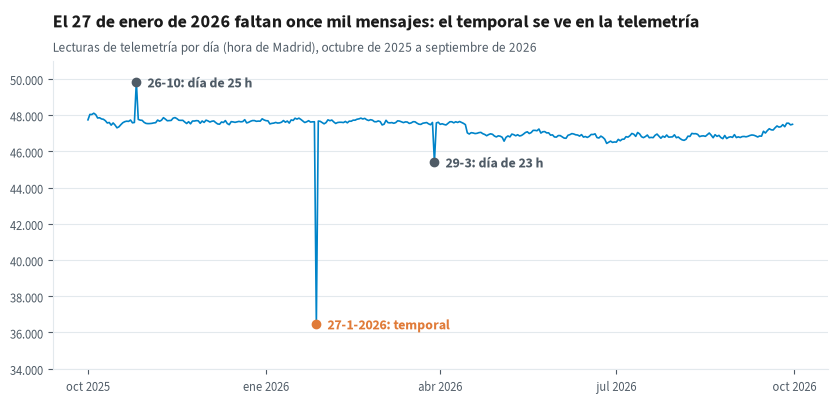

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(por_dia.index, por_dia.values, color=estilo.AZUL, linewidth=1.2)
for dia, texto, color in [("2026-01-27", "27-1-2026: temporal", estilo.NARANJA),
                          ("2025-10-26", "26-10: día de 25 h", estilo.TEXTO_2),
                          ("2026-03-29", "29-3: día de 23 h", estilo.TEXTO_2)]:
    t = pd.Timestamp(dia)
    ax.scatter([t], [por_dia[t]], color=color, zorder=3)
    ax.annotate(texto, (t, por_dia[t]), xytext=(8, -4), textcoords="offset points",
                color=color, fontsize=10, weight="bold")
ax.set_ylim(34_000, 51_000)
eje_es(ax)
eje_meses(ax)
ax.set_title("El 27 de enero de 2026 faltan once mil mensajes: el temporal se ve en la telemetría")
estilo.subtitulo(ax, "Lecturas de telemetría por día (hora de Madrid), octubre de 2025 a septiembre de 2026")
plt.show()

Tres señales sembradas, sin mirar ninguna bici:

- **27-1-2026:** un temporal tumba la red del operador de los módulos TM-B y esas bicis no
  mandan nada en todo el día. Volverá en el gráfico p de la Jornada 4.
- **26-10-2025 y 29-3-2026:** los cambios de hora. Un día de 25 horas trae más lecturas y uno
  de 23, menos. No es un defecto: es el reloj.
- **Las lecturas «del 1 de octubre de 2026»:** son de bicis del lote TM-C, que guardan la hora
  local como si fuera UTC. Al pasar a hora de Madrid se les suman dos horas de más y se salen
  del año. Lo veréis en el bloque 1.2.

In [9]:
# Liberamos la memoria: el resto del cuaderno no necesita la telemetría completa.
del tel, dia_local

## 2. Qué hay en `datos/avanzado`

Una carpeta por juego. Las carpetas `docente/` llevan las claves de solución y no se reparten,
así que no las listamos.

In [10]:
import pyarrow.parquet as pq

filas = []
for ruta in sorted(DATOS.rglob("*")):
    partes = ruta.relative_to(DATOS).parts
    if ruta.suffix not in (".csv", ".parquet") or "docente" in partes or "original" in partes:
        continue
    if ruta.suffix == ".parquet":
        n_filas = pq.ParquetFile(ruta).metadata.num_rows   # sin leer el fichero entero
    else:
        n_filas = len(pd.read_csv(ruta))
    filas.append({"carpeta": partes[0], "fichero": "/".join(partes[1:]),
                  "filas": n(n_filas), "MB": n(ruta.stat().st_size / 1e6, 1)})

inventario = pd.DataFrame(filas)
inventario

,carpeta,fichero,filas,MB
0,challenger,vuelos_previos.csv,23,"0,0"
1,embudo,caidas.csv,200,"0,0"
2,energia_bases,completo/quince_min_40_bases.parquet,2.803.200,"13,0"
3,energia_bases,diario.csv,29.200,"1,8"
4,energia_bases,horario.parquet,700.800,"2,8"
5,energia_bases,quince_min_b23.csv,70.080,"2,3"
6,energia_bases,quince_min_ejercicio.parquet,350.400,"2,0"
7,energia_bases,quince_min_muestra.csv,96,"0,0"
8,incidencias,incidencias.csv,34.623,"3,0"
9,indicadores,arl.csv,21,"0,0"


## 3. Los nueve juegos: periodo y para qué sirven

Para cada juego, su fichero principal, cuántas filas tiene y qué periodo cubre.

In [11]:
def periodo(serie):
    """Primer y último valor de una columna de fechas (texto AAAA-MM-DD o AAAA-MM)."""
    s = serie.dropna().astype(str).str[:10]
    return f"{s.min()} a {s.max()}"

energia = pd.read_csv(DATOS / "energia_bases" / "diario.csv")
uso = pd.read_csv(DATOS / "uso_meteo" / "viajes_sistema_hora.csv")
baterias = pd.read_csv(DATOS / "inventario_baterias" / "baterias.csv")
panel = pd.read_parquet(DATOS / "panel_baterias" / "panel.parquet",
                        columns=["mes", "bateria_id", "fallo_90d"])
incidencias = pd.read_csv(DATOS / "incidencias" / "incidencias.csv")
indicadores = pd.read_csv(DATOS / "indicadores" / "indicadores_mensuales.csv")
nodos = pd.read_csv(DATOS / "red_carriles" / "nodos.csv")
tramos = pd.read_csv(DATOS / "red_carriles" / "aristas.csv")
celdas = pd.read_csv(DATOS / "malla_h3" / "celdas.csv")

juegos = pd.DataFrame([
    ("Telemetría horaria", n(17_251_624), "2025-10-01 a 2026-09-30", "1.2 · 3.1 · 3.4"),
    ("Energía de las bases (diaria)", n(len(energia)), periodo(energia["fecha"]), "1.3 · 1.4 · 2.4 · 4.3 · 4.5"),
    ("Uso, meteorología y calendario", n(len(uso)), periodo(uso["fecha_local"]), "1.3 · 1.4 · 2.2"),
    ("Inventario de baterías", n(len(baterias)), periodo(baterias["fecha_alta"]), "2.3 · 4.5"),
    ("Panel mensual de baterías", n(len(panel)), periodo(panel["mes"]), "2.3 · 2.5"),
    ("Incidencias del servicio", n(len(incidencias)), periodo(incidencias["ts_apertura_utc"]), "4.3 · 4.5"),
    ("Indicadores mensuales", n(len(indicadores)), periodo(indicadores["mes"]), "4.2 · 4.3"),
    ("Red de carriles bici", f"{n(len(nodos))} cruces, {n(len(tramos))} tramos", "—", "3.3"),
    ("Malla H3-8 y contexto", n(len(celdas)), "un año (oct. 2025 a sep. 2026)", "3.1 · 3.2"),
], columns=["juego", "filas", "periodo", "bloques"])
juegos

,juego,filas,periodo,bloques
0,Telemetría horaria,17.251.624,2025-10-01 a 2026-09-30,1.2 · 3.1 · 3.4
1,Energía de las bases (diaria),29.200,2024-10-01 a 2026-09-30,1.3 · 1.4 · 2.4 · 4.3 · 4.5
2,"Uso, meteorología y calendario",26.304,2023-10-01 a 2026-09-30,1.3 · 1.4 · 2.2
3,Inventario de baterías,18.383,2021-03-01 a 2026-09-30,2.3 · 4.5
4,Panel mensual de baterías,351.000,2023-07 a 2026-09,2.3 · 2.5
5,Incidencias del servicio,34.623,2023-09-30 a 2026-09-30,4.3 · 4.5
6,Indicadores mensuales,36,2023-10 a 2026-09,4.2 · 4.3
7,Red de carriles bici,"180 cruces, 260 tramos",—,3.3
8,Malla H3-8 y contexto,595,un año (oct. 2025 a sep. 2026),3.1 · 3.2


Hay además dos ficheros pequeños de apoyo que no cuentan como juegos: unos 20.000 viajes
individuales con usuario seudónimo (`viajes_muestra/`, bloque 3.4) y la simulación del embudo
de Deming (`embudo/`, bloque 4.2).

## 4. ¿Trae cada juego su señal?

Una comprobación ligera por juego: nada de repetir el generador, solo mirar que lo sembrado
está donde debe. Para no destripar los ejercicios de las próximas jornadas, se miran señales
que ya salen en las diapositivas o que no resuelven nada.

In [12]:
# Energía: la base B-12 (diapositiva media-esconde) sube su mínimo nocturno sin que se note en la media.
energia["fecha"] = pd.to_datetime(energia["fecha"])
b12 = energia[energia["base_id"] == "B-12"].set_index("fecha")["2025-10-01":"2026-09-30"]
minimo_mes = b12["minimo_nocturno_kw"].resample("MS").mean()
print(f"B-12, mínimo nocturno medio: {n(minimo_mes.iloc[0], 1)} kW en octubre de 2025 → "
      f"{n(minimo_mes.iloc[-1], 1)} kW en septiembre de 2026")

# Uso: el ritmo de la semana (diapositiva tres-ritmos).
uso_dia = uso.groupby("fecha_local")["viajes"].sum()
dia_semana = pd.to_datetime(uso_dia.index).dayofweek
print(f"Viajes al día: {n(uso_dia[dia_semana < 5].mean())} de lunes a viernes, "
      f"{n(uso_dia[dia_semana == 6].mean())} los domingos")

B-12, mínimo nocturno medio: 14,9 kW en octubre de 2025 → 16,3 kW en septiembre de 2026
Viajes al día: 13.959 de lunes a viernes, 9.556 los domingos


In [13]:
# Baterías: las que siguen activas al cierre están «censuradas» (aún no sabemos cuándo fallarán).
activas = baterias["fecha_baja"].isna().sum()
print(f"Baterías: {n(len(baterias))} en la historia, {n(activas)} activas al cierre (censuradas)")

# Panel: fallo a 90 días muy raro, y los dos últimos meses aún sin etiqueta.
print(f"Panel: prevalencia de fallo a 90 días {pct(panel['fallo_90d'].mean())}; "
      f"meses sin etiqueta: {', '.join(sorted(panel.loc[panel['fallo_90d'].isna(), 'mes'].unique().tolist()))}")

# Incidencias: los días de tormenta se disparan las estaciones sin comunicación.
sin_com = incidencias[incidencias["tipo"] == "estación sin comunicación"]
por_dia_sc = bici.hora_local(sin_com["ts_apertura_utc"]).dt.date.value_counts()
print(f"Incidencias: {n(len(incidencias))}; estaciones sin comunicación, un día normal "
      f"{n(por_dia_sc.median())} y el peor día {n(por_dia_sc.max())}")

Baterías: 18.383 en la historia, 8.734 activas al cierre (censuradas)
Panel: prevalencia de fallo a 90 días 1,6 %; meses sin etiqueta: 2026-08, 2026-09
Incidencias: 34.623; estaciones sin comunicación, un día normal 2 y el peor día 37


In [14]:
import networkx as nx

# Indicadores: 36 meses completos, sin huecos.
print(f"Indicadores: {len(indicadores)} meses, {indicadores.isna().sum().sum()} valores vacíos; "
      f"tiempo de reparación de {n(indicadores['tmr_horas'].min(), 1)} a {n(indicadores['tmr_horas'].max(), 1)} h")

# Red: un solo grafo conexo (sus puntos frágiles, en la Jornada 3).
red = nx.from_pandas_edgelist(tramos, "nodo_a", "nodo_b")
print(f"Red: {red.number_of_nodes()} cruces, {red.number_of_edges()} tramos, "
      f"{n(tramos['longitud_m'].sum() / 1000)} km; ¿conexa? {nx.is_connected(red)}")

# Malla H3: tasa media de pérdidas de señal por cada 1.000 viajes.
tasa = 1000 * celdas["perdidas_senal"].sum() / celdas["viajes_que_cruzan"].sum()
print(f"Malla: {len(celdas)} celdas H3-8; {n(tasa, 2)} pérdidas de señal por 1.000 viajes")

Indicadores: 36 meses, 0 valores vacíos; tiempo de reparación de 45,9 a 63,7 h
Red: 180 cruces, 260 tramos, 235 km; ¿conexa? True
Malla: 595 celdas H3-8; 2,11 pérdidas de señal por 1.000 viajes


## Qué os lleváis

- Los datos ya están hechos, con semilla 2026: todo el mundo trabaja con los mismos ficheros
  y saca las mismas cifras que las diapositivas.
- Antes de analizar, contad: cuántas filas, de cuándo a cuándo, cuántas esperabais. Solo con
  contar lecturas por día han salido un temporal, dos cambios de hora y un lote de módulos
  con el reloj cambiado.
- Cada juego trae defectos sembrados y su clave de solución aparte. Cuando encontréis algo,
  sabremos si es de verdad. En la vida real casi nunca se puede saber.